# Rain Prediction — Imputation / Data-Quality Audit

**Decision notebook.** EXP-002 concluded the operating-point F1 ceiling is *data-limited*, with
a k-NN Bayes-error proxy of ~0.15 measured in the **same-day, MICE-imputed** feature space. Mais
une large part du signal est *reconstruite*, pas observée : dans `weatherAUS_trend_grouped.csv`
(la sortie de `3.preprocessing_trend_group.ipynb`, **avant** imputation), `Sunshine`,
`Evaporation`, `Cloud3pm` et `Cloud9am` sont massivement manquants — et figurent parmi les
meilleurs prédicteurs du modèle.

**Question :** quelle part du plafond vient du **bruit d'imputation** (→ investir dans la donnée
paie, garder des indicatrices de manquant) vs de l'**ambiguïté météo réelle** (→ arrêter de
creuser ici ; pivoter vers des features temporelles / spatiales) ?

Trois tests bon marché répondent :
- **A.** Les indicatrices `*__imp` améliorent-elles le F1 ? (le manquant est-il lui-même du signal ?)
- **B.** La prédictibilité se dégrade-t-elle avec le nombre de features clés imputées ? (dose-réponse)
- **C.** Le plancher de bruit est-il plus bas sur les lignes complètement observées ?

Le masque de manquants est reconstruit en comparant les **deux sorties du pipeline** :
`weatherAUS_trend_grouped.csv` (pré-imputation, NaN conservés) et les matrices
`weatherAUS_{X,y}_{train,test}.csv` (post-MICE, splitées). Les deux frames partagent exactement
les mêmes lignes et la clé `(Date, Location)`, donc aucune jointure approximative n'est nécessaire.

Outputs are mirrored to `AUDIT_result.txt`; figures saved under `figures/` as `audit_*`;
modèles sérialisés dans `../../models/`.


## 1. Imports and constants

In [14]:
import os
import sys
import warnings
from datetime import datetime, timezone

import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (
    classification_report, f1_score, precision_score, recall_score, roc_auc_score,
)

import xgboost as xgb
from xgboost import XGBClassifier

warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')

# --- GPU configuration ---
def _gpu_available():
    try:
        dtest = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, dtest, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); falling back to CPU.')
        return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
SEARCH_N_JOBS = 1 if USE_GPU else -1

XGB_KW = dict(tree_method='hist', device=DEVICE, eval_metric='logloss',
              random_state=RANDOM_STATE, n_jobs=-1)

def make_xgb(**overrides):
    params = dict(XGB_KW); params.update(overrides)
    return XGBClassifier(**params)

# Frozen deployment-candidate config from EXP-2026-06-15-002.
V2_PARAMS = dict(
    max_depth=6, min_child_weight=10, gamma=2.0, reg_lambda=20, reg_alpha=0.5,
    learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_estimators=800,
)
AUDIT_THRESHOLD = 0.65   # v2 PR-crossover operating point

print(f'xgboost {xgb.__version__} | device: {DEVICE}')

### Output setup

In [15]:
os.makedirs('figures', exist_ok=True)
_RESULT_PATH = 'AUDIT_result.txt'
_RESULT_FILE = open(_RESULT_PATH, 'w', encoding='utf-8')

class _Tee:
    def __init__(self, *s): self._s = s
    def write(self, d):
        for s in self._s: s.write(d)
    def flush(self):
        for s in self._s: s.flush()
    def isatty(self): return False

_ORIG_STDOUT = sys.stdout
sys.stdout = _Tee(_ORIG_STDOUT, _RESULT_FILE)
print('# Imputation / data-quality audit — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

def log_section(title):
    bar = '=' * 72
    print(f'\n{bar}\n{title}\n{bar}')

def save_fig(name, fig=None):
    fig = fig or plt.gcf()
    path = f'figures/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')

# --- Sérialisation des modèles ---------------------------------------------
# Chaque étape du notebook est enregistrée dans <repo>/models sous forme d'un
# dict joblib : le modèle + les métadonnées nécessaires pour le rejouer.
MODEL_DIR = os.environ.get('WEATHER_MODEL_DIR', '../../models')
os.makedirs(MODEL_DIR, exist_ok=True)
NOTEBOOK = 'EXP-003_XGB_audit'

def save_model(obj, name, **meta):
    """Sauvegarde `obj` dans MODEL_DIR/<name>.joblib avec ses métadonnées."""
    path = f'{MODEL_DIR}/{name}.joblib'
    joblib.dump({'model': obj,
                 'notebook': NOTEBOOK,
                 'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
                 **meta}, path)
    print(f'  [saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)]')

Running on Colab: True
xgboost 3.4.0 | device: cuda
# Imputation / data-quality audit — numerical outputs
# Generated: 2026-08-11 12:52:51

2. Data loading (sorties du pipeline)
X_train (113506, 29) | X_test (25314, 29)
Train 2007-11-01 -> 2015-12-31 | Test 2016-01-01 -> 2017-06-25
Stations : 49 | pluie train 21.9574% / test 22.6950%
Pré-imputation : 138,820 lignes x 27 colonnes (292,371 NaN conservés)
<xml><var name="_dummy_ipython_val"  />
<var name="_dummy_special_var"  />
<var name="AUDIT_THRESHOLD" type="float" qualifier="builtins" value="0.65" />
<var name="DATA_DIR" type="str" qualifier="builtins" value="../../data" />
<var name="DEVICE" type="str" qualifier="builtins" value="cuda" />
<var name="IN_COLAB" type="bool" qualifier="builtins" value="True" />
<var name="MODEL_DIR" type="str" qualifier="builtins" value="../../models" />
<var name="NOTEBOOK" type="str" qualifier="builtins" value="EXP-003_XGB_audit" />
<var name="RANDOM_STATE" type="int" qualifier="builtins" value="42" /

## 2. Chargement — pré-imputation (`trend_grouped`) + post-imputation (matrices du pipeline)

In [16]:
log_section('2. Data loading (sorties du pipeline)')

# Sorties du pipeline, dans <repo>/data :
#   3.preprocessing_trend_group.ipynb -> weatherAUS_trend_grouped.csv
#   4_preprocessing_imputation.ipynb  -> weatherAUS_MICE_cyclic.csv
#                                        weatherAUS_X_train.csv / weatherAUS_y_train.csv
#                                        weatherAUS_X_test.csv  / weatherAUS_y_test.csv
DATA_DIR = os.environ.get('WEATHER_DATA_DIR', '../../data')

# Matrices déjà splitées, encodées (LabelEncoder) et scalées (RobustScaler ajusté
# sur le train uniquement) par 4_preprocessing_imputation.ipynb.
X_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_train.csv')
X_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_test.csv')
y_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_train.csv').squeeze('columns').astype(int)
y_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_test.csv').squeeze('columns').astype(int)

# Index (Date, Location) aligné ligne à ligne sur X_train / X_test :
# weatherAUS_MICE_cyclic.csv est trié par Date et le pipeline y applique le même
# seuil TEST_CUTOFF, donc ses len(X_train) premières lignes SONT celles de X_train.
meta = pd.read_csv(f'{DATA_DIR}/weatherAUS_MICE_cyclic.csv',
                   usecols=['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm'], parse_dates=['Date'])
meta = meta[['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']]
assert len(meta) == len(X_train) + len(X_test), 'X_train/X_test ne recouvrent pas MICE_cyclic'
meta_train = meta.iloc[:len(X_train)].reset_index(drop=True)
meta_test  = meta.iloc[len(X_train):].reset_index(drop=True)
assert (meta_train['Date'] < TEST_CUTOFF).all(), 'lignes de train postérieures au seuil'
assert (meta_test['Date'] >= TEST_CUTOFF).all(), 'lignes de test antérieures au seuil'

print(f'X_train {X_train.shape} | X_test {X_test.shape}')
print(f'Train {meta_train["Date"].min().date()} -> {meta_train["Date"].max().date()} | '
      f'Test {meta_test["Date"].min().date()} -> {meta_test["Date"].max().date()}')
print(f'Stations : {meta["Location"].nunique()} | pluie train {y_train.mean():.4%} / test {y_test.mean():.4%}')

# Frame AVANT imputation (mêmes lignes, NaN d'origine conservés) : sert à
# reconstruire les features retardées / voisines sans réutiliser de valeur
# reconstruite par MICE.
pre = pd.read_csv(f'{DATA_DIR}/weatherAUS_trend_grouped.csv', parse_dates=['Date'])
assert len(pre) == len(meta), 'weatherAUS_trend_grouped.csv désaligné du pipeline'
print(f'Pré-imputation : {pre.shape[0]:,} lignes x {pre.shape[1]} colonnes '
      f'({pre.isna().sum().sum():,} NaN conservés)')

## 3. Missingness profiling

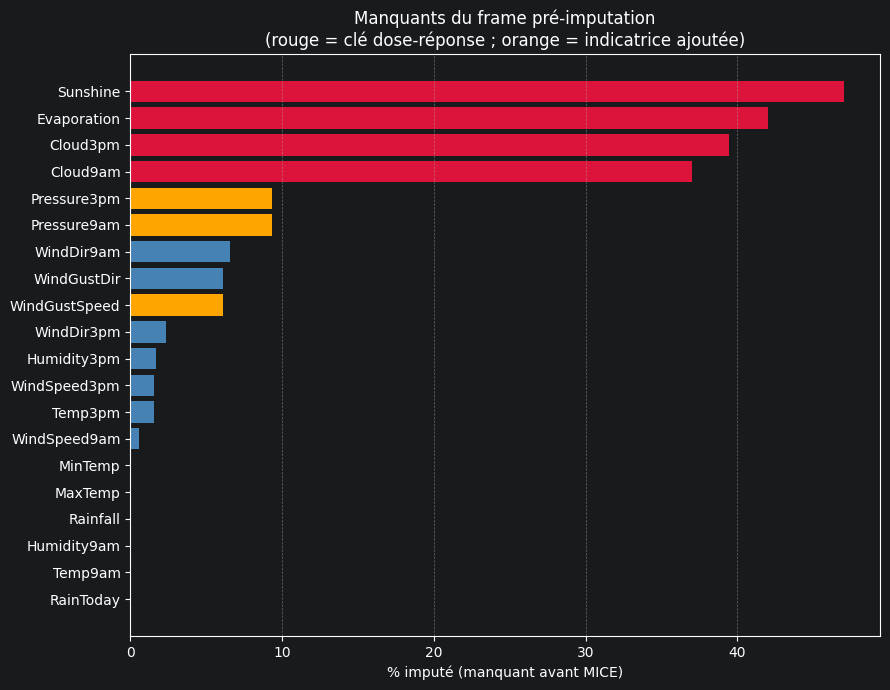

In [17]:
log_section('3. Missingness profiling (frame pré-imputation)')

# Colonnes de mesure dont on audite le taux de manquant. weatherAUS_trend_grouped.csv
# contient déjà exactement les lignes retenues pour la modélisation, donc aucun
# filtrage supplémentaire n'est nécessaire (contrairement au CSV brut d'origine).
RAW_MEAS_COLS = [
    'MinTemp','MaxTemp','Rainfall','Evaporation','Sunshine','WindGustSpeed',
    'WindSpeed9am','WindSpeed3pm','Humidity9am','Humidity3pm','Pressure9am','Pressure3pm',
    'Cloud9am','Cloud3pm','Temp9am','Temp3pm','WindGustDir','WindDir9am','WindDir3pm','RainToday',
]

miss = (pre[RAW_MEAS_COLS].isna().mean() * 100).sort_values(ascending=False)
print(f'Taux de manquant (%) parmi les {len(pre):,} lignes de modélisation :')
print(miss.round(1).to_string())

# Features du modèle lourdement imputées -> on leur ajoute une indicatrice.
HEAVY_COLS = [c for c in RAW_MEAS_COLS if miss[c] >= 5.0
              and c in ['Sunshine','Evaporation','Cloud3pm','Cloud9am',
                        'Pressure9am','Pressure3pm','WindGustSpeed']]
KEY_IMPUTED = ['Sunshine','Evaporation','Cloud3pm','Cloud9am']   # le bloc le plus manquant
print(f'\nIndicator features will be added for: {HEAVY_COLS}')
print(f'Dose-response key columns           : {KEY_IMPUTED}')

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['crimson' if c in KEY_IMPUTED else ('orange' if c in HEAVY_COLS else 'steelblue')
          for c in miss.index]
ax.barh(miss.index[::-1], miss.values[::-1], color=colors[::-1])
ax.set_xlabel('% imputé (manquant avant MICE)')
ax.set_title('Manquants du frame pré-imputation\n(rouge = clé dose-réponse ; orange = indicatrice ajoutée)')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('audit_01_missingness_profile', fig)
plt.show()

## 4. Build imputation mask and indicator features

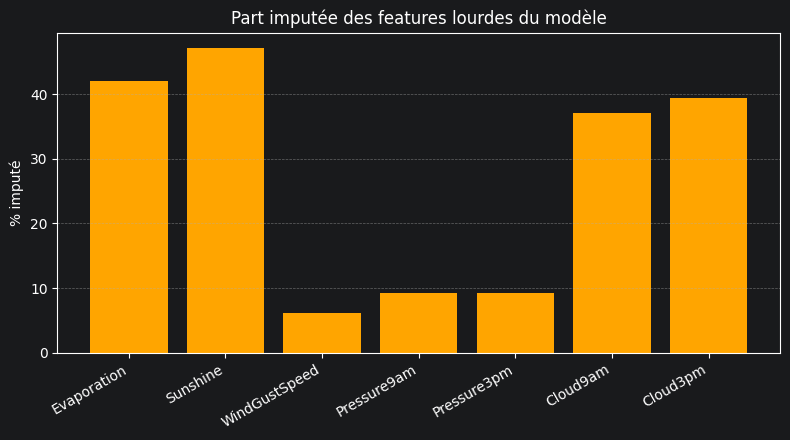

In [18]:
log_section('4. Imputation mask + indicators')

# (Date, Location) est une clé unique et identique dans les deux frames du pipeline,
# donc le masque de manquant se réaligne exactement sur l'ordre des lignes de
# X_train / X_test — pas de merge many-to-many ni de ligne orpheline.
imp_cols = [f'{c}__imp' for c in RAW_MEAS_COLS]
pre_key = pd.MultiIndex.from_frame(pre[['Date', 'Location']])
assert pre_key.is_unique, '(Date, Location) non unique dans le frame pré-imputation'

ind_all = pd.DataFrame({f'{c}__imp': pre[c].isna().astype(int).to_numpy() for c in RAW_MEAS_COLS},
                       index=pre_key)
ind_all = ind_all.reindex(pd.MultiIndex.from_frame(meta[['Date', 'Location']]))
unmatched = int(ind_all.isna().any(axis=1).sum())
ind_all = ind_all.fillna(0).astype(int).reset_index(drop=True)
print(f'Masque réaligné sur {len(ind_all):,} lignes | non appariées (remplies à 0) : {unmatched:,}')

# Compteur dose-réponse : combien de prédicteurs CLÉS ont été imputés sur cette ligne.
n_key_imputed = ind_all[[f'{c}__imp' for c in KEY_IMPUTED]].sum(axis=1)
nkey_train = n_key_imputed.iloc[:len(X_train)].reset_index(drop=True)
nkey_test  = n_key_imputed.iloc[len(X_train):].reset_index(drop=True)
print('\nDistribution de n_key_imputed (0..4) :')
print(n_key_imputed.value_counts().sort_index().to_string())

share = (ind_all[[f'{c}__imp' for c in HEAVY_COLS]].mean() * 100).round(1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(list(HEAVY_COLS), [share[f'{c}__imp'] for c in HEAVY_COLS], color='orange')
ax.set_ylabel('% imputé'); ax.set_title('Part imputée des features lourdes du modèle')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save_fig('audit_02_imputed_share', fig)
plt.show()

## 5. Feature engineering (base v2 + indicatrices)

Base = les 23 colonnes du pipeline retenues depuis EXP-001, plus les deux différences
intra-journalières de EXP-002 (calculées sur les valeurs **non scalées**) → 25 features.
`PLUS` y ajoute les indicatrices `*__imp`.


In [19]:
log_section('5. Feature engineering (base v2 + indicatrices)')

# Features de tendance intra-journalière. Elles sont calculées sur les valeurs
# NON scalées de weatherAUS_MICE_cyclic.csv : une différence de colonnes déjà
# passées au RobustScaler (échelles distinctes) ne serait pas la même grandeur.
for X, m in ((X_train, meta_train), (X_test, meta_test)):
    X['Pressure_diff'] = (m['Pressure3pm'] - m['Pressure9am']).to_numpy()
    X['Temp_diff']     = (m['Temp3pm']     - m['Temp9am']).to_numpy()

# Le pipeline livre 29 colonnes. On retire les mêmes que l'étude LR pour que les
# expériences EXP-001..007 restent comparables entre elles :
DROP_COLS = [
    'WindGustDir', 'WindDir9am', 'WindDir3pm',  # labels encodés ; les sin/cos sont conservés
    'RainToday',                                # quasi-fuite (on donne déjà le reste de la journée)
    'Humidity9am',                              # on garde Humidity3pm (plus prédictive)
    'Month',                                    # redondant avec Date_sin / Date_cos
]
BASE_FEATURES = [c for c in X_train.columns if c not in DROP_COLS]
IND_FEATURES  = [f'{c}__imp' for c in HEAVY_COLS]
PLUS_FEATURES = BASE_FEATURES + IND_FEATURES

n_tr = len(X_train)
X_train = pd.concat([X_train[BASE_FEATURES],
                     ind_all.iloc[:n_tr][IND_FEATURES].reset_index(drop=True)], axis=1)
X_test  = pd.concat([X_test[BASE_FEATURES],
                     ind_all.iloc[n_tr:][IND_FEATURES].reset_index(drop=True)], axis=1)

assert list(X_train.columns) == PLUS_FEATURES == list(X_test.columns)
print(f'BASE features : {len(BASE_FEATURES)}')
print(f'+ indicateurs : {len(IND_FEATURES)} -> PLUS = {len(PLUS_FEATURES)}')

## 6. Split chronologique (fourni par le pipeline) + config

Le découpage `train < 2016-01-01 <= test` vient de `4_preprocessing_imputation.ipynb`.


In [20]:
log_section('6. Split chronologique (fourni par le pipeline)')

y_train_i = y_train
y_test_i  = y_test

pos_rate = float(y_train_i.mean())
SPW = (1 - pos_rate) / pos_rate
V2_PARAMS['scale_pos_weight'] = SPW
ts_cv = TimeSeriesSplit(n_splits=5)
print(f'Train {len(X_train):,} | Test {len(X_test):,} | scale_pos_weight {SPW:.4f}')
print(f'Lignes de test avec >=1 prédicteur clé imputé : {(nkey_test > 0).mean():.1%}')

## 7. Experiment A — do `*_was_imputed` indicators help?

If missingness carries signal (e.g. some stations never report sunshine), adding binary
imputation indicators should lift CV/test F1. A null result means missingness is not directly
informative.

In [21]:
log_section('7. Experiment A — missingness indicators')

def evaluate(name, cols):
    m = make_xgb(**V2_PARAMS)
    cv_f1 = cross_val_score(m, X_train[cols], y_train_i, cv=ts_cv,
                            scoring='f1', n_jobs=SEARCH_N_JOBS).mean()
    m.fit(X_train[cols], y_train_i)
    proba = m.predict_proba(X_test[cols])[:, 1]
    pred = (proba >= AUDIT_THRESHOLD).astype(int)
    row = dict(model=name, n_feat=len(cols), cv_f1=round(cv_f1, 4),
               test_f1=round(f1_score(y_test_i, pred), 4),
               precision=round(precision_score(y_test_i, pred), 4),
               recall=round(recall_score(y_test_i, pred), 4),
               roc_auc=round(roc_auc_score(y_test_i, proba), 4))
    return m, row, proba

m_base, row_base, proba_base = evaluate('BASE (no indicators)', BASE_FEATURES)
m_plus, row_plus, proba_plus = evaluate('PLUS indicators',      PLUS_FEATURES)

expA = pd.DataFrame([row_base, row_plus])
print(expA.to_string(index=False))
indicator_gain = row_plus['cv_f1'] - row_base['cv_f1']
print(f'\nIndicator CV-F1 gain: {indicator_gain:+.4f}')

save_model(m_base, 'EXP-003_01_base',
           features=BASE_FEATURES, stage='config v2 gelée, sans indicatrices de manquant',
           params=V2_PARAMS, threshold=AUDIT_THRESHOLD, metrics=row_base)
save_model(m_plus, 'EXP-003_02_plus_indicators',
           features=PLUS_FEATURES, stage='config v2 gelée + indicatrices *__imp',
           params=V2_PARAMS, threshold=AUDIT_THRESHOLD, metrics=row_plus,
           indicator_cv_f1_gain=float(indicator_gain))

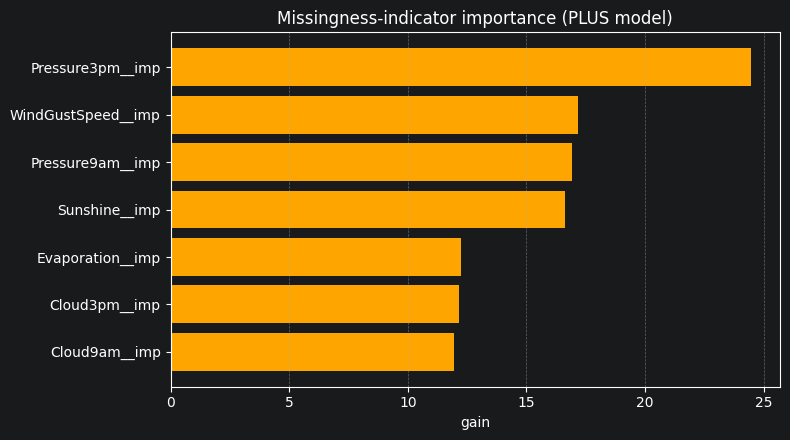

In [22]:
# Gain importance of the indicator features within the PLUS model.
gain = m_plus.get_booster().get_score(importance_type='gain')
ind_gain = pd.DataFrame(
    [(c, gain.get(c, 0.0)) for c in IND_FEATURES],
    columns=['indicator', 'gain']).sort_values('gain', ascending=False)
print('\nIndicator-feature gain (within PLUS model):')
print(ind_gain.to_string(index=False, float_format='%.2f'))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(ind_gain['indicator'][::-1], ind_gain['gain'][::-1], color='orange')
ax.set_xlabel('gain'); ax.set_title('Missingness-indicator importance (PLUS model)')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('audit_03_indicator_importance', fig)
plt.show()

## 8. Experiment B — predictability vs imputation count (dose-response)

Bucket the test rows by how many of the 4 key predictors were imputed (0–4) and score the BASE
model per bucket. **Monotone degradation** of ROC-AUC with imputation count is direct evidence
that imputed rows carry more irreducible error — i.e. imputation noise contributes to the ceiling.
ROC-AUC is the primary (threshold-free) read; F1 is shown for reference.

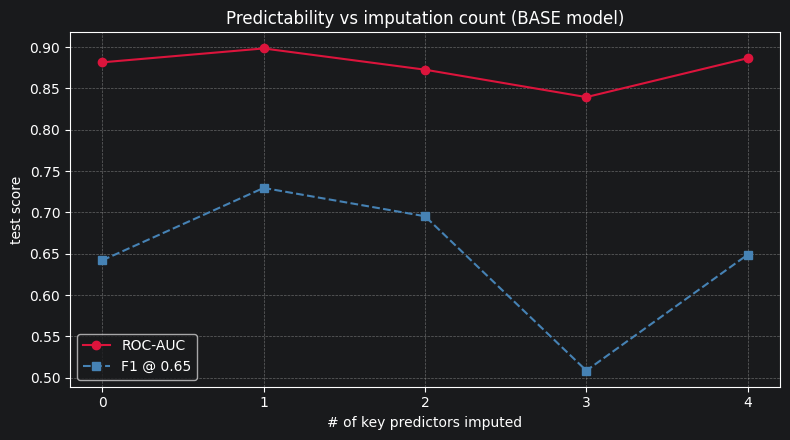

In [23]:
log_section('8. Experiment B — dose-response by imputation count')

rows = []
for k in range(5):
    sel = (nkey_test == k).values
    n = int(sel.sum())
    if n < 50 or y_test_i[sel].nunique() < 2:
        rows.append(dict(n_key_imputed=k, n_rows=n, rain_rate=np.nan, roc_auc=np.nan, f1=np.nan))
        continue
    pr = proba_base[sel]
    yt = y_test_i[sel]
    rows.append(dict(
        n_key_imputed=k, n_rows=n, rain_rate=round(float(yt.mean()), 4),
        roc_auc=round(roc_auc_score(yt, pr), 4),
        f1=round(f1_score(yt, (pr >= AUDIT_THRESHOLD).astype(int)), 4)))
doseB = pd.DataFrame(rows)
print(doseB.to_string(index=False))

valid = doseB.dropna(subset=['roc_auc'])
roc_drop = float(valid['roc_auc'].iloc[0] - valid['roc_auc'].iloc[-1])
print(f'\nROC-AUC drop, 0 imputed -> {int(valid["n_key_imputed"].iloc[-1])} imputed: {roc_drop:+.4f}')

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(valid['n_key_imputed'], valid['roc_auc'], 'o-', color='crimson', label='ROC-AUC')
ax.plot(valid['n_key_imputed'], valid['f1'], 's--', color='steelblue', label=f'F1 @ {AUDIT_THRESHOLD}')
ax.set_xlabel('# of key predictors imputed'); ax.set_ylabel('test score')
ax.set_title('Predictability vs imputation count (BASE model)')
ax.set_xticks(range(5)); ax.legend(); ax.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('audit_04_dose_response', fig)
plt.show()

## 9. Experiment C — noise floor: full vs fully-observed

Recompute the EXP-002 k-NN Bayes-error proxy on (i) a full-train subsample and (ii) the
fully-observed subsample (`n_key_imputed == 0`). A **lower** proxy on observed rows means
imputation inflates the local class overlap — the floor is partly an artifact of imputation.

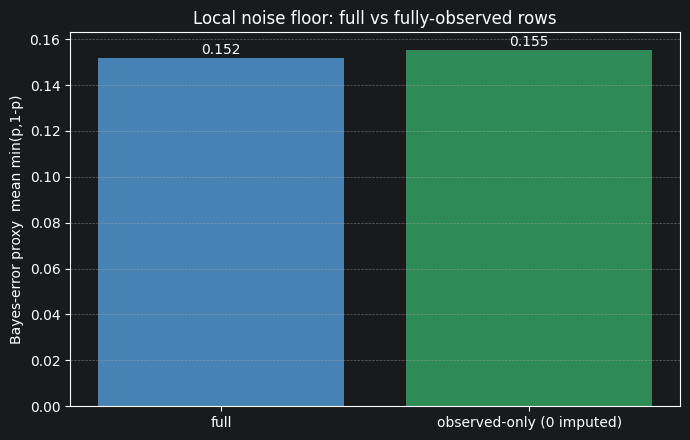

In [24]:
log_section('9. Experiment C — noise floor (full vs observed-only)')
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

def bayes_proxy(Xdf, y, k=25, n_sub=20000, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(Xdf), size=min(n_sub, len(Xdf)), replace=False)
    Xs = StandardScaler().fit_transform(Xdf.iloc[idx].values)
    ys = y.iloc[idx].values
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Xs)
    nbr = nn.kneighbors(Xs, return_distance=False)[:, 1:]
    p = ys[nbr].mean(axis=1)
    pred = (p >= 0.5).astype(int)
    return dict(n=len(idx), knn_f1=round(f1_score(ys, pred), 4),
                knn_acc=round((pred == ys).mean(), 4),
                bayes_err=round(float(np.mean(np.minimum(p, 1 - p))), 4))

full = bayes_proxy(X_train[BASE_FEATURES], y_train_i)
obs_sel = (nkey_train == 0).values
clean = bayes_proxy(X_train[BASE_FEATURES][obs_sel].reset_index(drop=True),
                    y_train_i[obs_sel].reset_index(drop=True))
floorC = pd.DataFrame([dict(subset='full', **full), dict(subset='observed-only (0 imputed)', **clean)])
print(floorC.to_string(index=False))
bayes_drop = full['bayes_err'] - clean['bayes_err']
print(f'\nBayes-error proxy drop (full -> observed): {bayes_drop:+.4f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(floorC['subset'], floorC['bayes_err'], color=['steelblue', 'seagreen'])
ax.set_ylabel('Bayes-error proxy  mean min(p,1-p)')
ax.set_title('Local noise floor: full vs fully-observed rows')
for i, v in enumerate(floorC['bayes_err']):
    ax.text(i, v + 0.002, f'{v:.3f}', ha='center')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('audit_05_noise_floor_comparison', fig)
plt.show()

## 10. Verdict

In [25]:
log_section('10. Verdict')

# Decision thresholds (any one triggering => imputation noise is material).
THR_IND, THR_DOSE, THR_FLOOR = 0.005, 0.030, 0.020
signals = {
    'A: indicator CV-F1 gain >= 0.005': indicator_gain >= THR_IND,
    'B: ROC-AUC drop (0->max imputed) >= 0.030': roc_drop >= THR_DOSE,
    'C: Bayes-proxy drop (full->observed) >= 0.020': bayes_drop >= THR_FLOOR,
}
print('Evidence:')
print(f'  A indicator CV-F1 gain        : {indicator_gain:+.4f}  -> {signals["A: indicator CV-F1 gain >= 0.005"]}')
print(f'  B ROC-AUC dose-response drop  : {roc_drop:+.4f}  -> {signals["B: ROC-AUC drop (0->max imputed) >= 0.030"]}')
print(f'  C Bayes-proxy full->observed  : {bayes_drop:+.4f}  -> {signals["C: Bayes-proxy drop (full->observed) >= 0.020"]}')

n_fire = sum(signals.values())
print(f'\nSignals firing: {n_fire}/3')
if n_fire >= 2:
    print('\nVERDICT: IMPUTATION NOISE is a MATERIAL contributor to the ceiling.')
    print('  -> Keep missingness-indicator features in the model.')
    print('  -> Invest in a causal / better imputer, or restrict to better-observed stations.')
    print('  -> The data-limited ceiling can be partly bought back with data quality.')
elif n_fire == 1:
    print('\nVERDICT: MIXED. One axis suggests imputation noise; treat as a minor lever.')
    print('  -> Add indicators (cheap), but expect the larger gains from NEW inputs (temporal/spatial).')
else:
    print('\nVERDICT: GENUINE AMBIGUITY dominates; imputation is NOT the bottleneck.')
    print('  -> Stop optimizing data quality here.')
    print('  -> Pivot to new signal: temporal/lagged features, spatial context, or a new target.')

## Finalization

In [26]:
log_section('Finalization')
print(f'Results file: {_RESULT_PATH}')
fig_files = sorted(f for f in os.listdir('figures') if f.startswith('audit_'))
print(f'Audit figures saved ({len(fig_files)}):')
for f in fig_files:
    print(f'  figures/{f}')

model_files = sorted(f for f in os.listdir(MODEL_DIR) if f.startswith('EXP-003_'))
print(f'\nModels saved ({len(model_files)}) in {MODEL_DIR}:')
for f in model_files:
    print(f'  {f}')

sys.stdout = _ORIG_STDOUT
_RESULT_FILE.close()
print(f'\nDone. See {_RESULT_PATH} and figures/ for outputs.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>